# Model HEXACO rankings with 2PLM-RANK

Fit 2PLM-RANK to observed best–worst choices and examine statement
discrimination and intercepts.

## Define the endorsement model

Let $p$ index respondents, $j$ index statements and $t(j)$ name the trait
measured by statement $j$. In 2PLM-RANK, the log odds of endorsing a
statement are

$$
\ell_{pj}=q_j a_j\theta_{p,t(j)}-b_j.
$$

Here $\theta_{p,t(j)}$ is the trait score, $a_j>0$ is the loading magnitude,
$q_j\in\{-1,+1\}$ is the keying sign and $b_j$ is the statement intercept.
Larger $b_j$ lowers endorsement. The odds are $w_{pj}=\exp(\ell_{pj})$,
so endorsement of the statement on its own would have probability
$w_{pj}/(1+w_{pj})$.

Within a block, the probability of selecting $j$ next is its odds divided
by the sum of the odds of all statements still available. Write $Y_{pb}$
for the order reported by respondent $p$ in block $b$. For example,

$$
P(Y_{pb}=(A,B,C))=
\frac{w_{pA}}{w_{pA}+w_{pB}+w_{pC}}\,
\frac{w_{pB}}{w_{pB}+w_{pC}}.
$$

The first factor selects $A$ from all three statements. The second selects
$B$ from the remaining two. $C$ is the only remaining statement. The data
record most- and least-preferred choices, which specify a unique order
in a triplet. [Zheng et al. (2024)](https://doi.org/10.3758/s13428-023-02315-x)

## Read the forced-choice data and design

The bundled FC3 data contain 200 respondents and 20 HEXACO triplets from
[Li et al. (2025)](https://doi.org/10.1177/10944281241229784). The design names
each statement, its position, trait and keying. Each answer records the
most- and least-preferred positions. With three statements, those two
positions determine the full order.

In [1]:
import seaborn as sns

import pyfcirt as fc

sns.set_theme(style="ticks")

example = fc.load_example("hexaco_fc3", model="TwoPLRank")
design = example.data.design
responses = example.data.responses.frame
design.head(3)

,block_id,position,statement_id,trait,keying
0,B1,1,i1,honestyhumility,-1
1,B1,2,i2,openness,-1
2,B1,3,i3,agreeableness,-1


In [2]:
responses.head(3)

,person_id,block_id,response
0,1,B1,"[3, None, 1]"
1,1,B2,"[3, None, 2]"
2,1,B3,"[1, None, 2]"


In [3]:
model = fc.Model()
model.add_fc(
    design,
    responses,
    format="block_long",
    response_format="mole",
    model="TwoPLRank",
)
model.prepare()
print(model.summary())

Model: TwoPLRank
200 people, 6 traits, 20 blocks, 60 statements
Observations: 4,000 block events
Measurements:
  mole: 20 blocks, size=3, categories=6
Population:
  theta ~ MvNormal(mu=0, cov=R)
  R [6 x 6] ~ LKJCorr(n=6, eta=1)
Priors:
    loading [60] ~ LogNormal(mu=0, sigma=0.5)
    statement_intercept [40] ~ Normal(mu=0, sigma=2)
Constraints:
    statement_intercept: fixed=0 [20 fixed]


The summary shows the best–worst response format and the reference intercepts for the sequential model.

## Fit the model

Use four chains so you can compare their results after fitting.

In [4]:
model.fit(draws=1200, tune=1800, chains=4);

## Diagnose the chains

Check that the chains agree before interpreting the statement estimates. The rank and density panels inspect one respondent's Honesty–Humility score.

In [5]:
import arviz as az
import numpy as np

posterior = model.idata.posterior.to_dataset().reset_coords(drop=True)
with np.errstate(invalid="ignore", divide="ignore"):
    r_hat = az.rhat(posterior).max().to_array().max().item()
    bulk = az.ess(posterior, method="bulk").min().to_array().min().item()
    tail = az.ess(posterior, method="tail").min().to_array().min().item()

print(f"Max R-hat: {r_hat:.3f}")
print(f"Min bulk / tail ESS: {bulk:.0f} / {tail:.0f}")
print("Divergences:", int(model.idata.sample_stats.diverging.sum()))

Max R-hat: 1.007
Min bulk / tail ESS: 889 / 1458
Divergences: 0


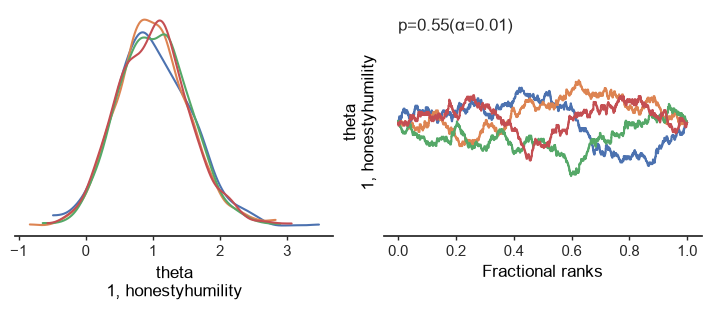

In [6]:
import arviz_plots as azp
import matplotlib.pyplot as plt

azp.plot_rank_dist(
    model.idata,
    var_names=["theta"],
    coords={
        "person": [model.idata.posterior.person.values[0]],
        "trait": ["honestyhumility"],
    },
    backend="matplotlib",
    compact=False,
    figure_kwargs={"figsize": (7, 3), "layout": "constrained"},
)
plt.show()

## Interpret the statement coefficients

Read the discrimination and intercept for each statement in the first two
triplets. Discrimination controls how strongly the trait influences
endorsement. The intercept shifts endorsement up or down on the log-odds
scale. The reference statement in each block has intercept zero.

In [7]:
model.coef(blocks=["B1", "B2"], kind="stats", round_to=2)

mean    sd  hdi95_lb  \
unit statement trait           parameter                                   
B1   i1        honestyhumility loading              1.41  0.28      0.85   
     i2        openness        loading              0.59  0.16      0.29   
     i3        agreeableness   loading              0.53  0.16      0.23   
     i1        honestyhumility statement_intercept  0.00   NaN       NaN   
     i2        openness        statement_intercept -1.09  0.20     -1.50   
     i3        agreeableness   statement_intercept -1.70  0.22     -2.14   
B2   i4        emotionality    loading              0.53  0.16      0.25   
     i5        openness        loading              0.75  0.18      0.41   
     i6        agreeableness   loading              0.52  0.14      0.27   
     i4        emotionality    statement_intercept  0.00   NaN       NaN   
     i5        openness        statement_intercept  0.03  0.16     -0.27   
     i6        agreeableness   statement_intercept  0.05  0.15     -0.24   

                                                    hdi95_ub  
unit statement trait           parameter                      
B1   i1        honestyhumility loading                  1.94  
     i2        openness        loading                  0.90  
     i3        agreeableness   loading                  0.85  
     i1        honestyhumility statement_intercept       NaN  
     i2        openness        statement_intercept     -0.72  
     i3        agreeableness   statement_intercept     -1.29  
B2   i4        emotionality    loading                  0.84  
     i5        openness        loading                  1.09  
     i6        agreeableness   loading                  0.81  
     i4        emotionality    statement_intercept       NaN  
     i5        openness        statement_intercept      0.35  
     i6        agreeableness   statement_intercept      0.35

## Read statement endorsement curves

Use one block to see how its statements relate to their respective traits.
The horizontal axis gives the score on each statement's own trait. Each
curve evaluates the endorsement probability at the posterior mean
discrimination and intercept. The block probability uses their relative
odds, as shown above.

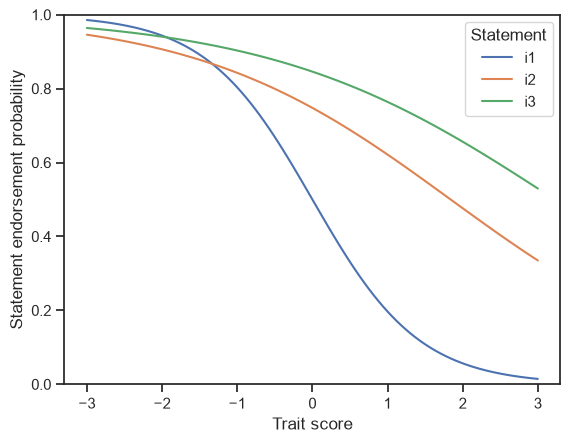

In [8]:
import pandas as pd
from scipy.special import expit

table = model.coef(blocks=["B1"], kind="stats", round_to="none").reset_index()
estimates = table.pivot(index="statement", columns="parameter", values="mean")
keying = design.set_index("statement_id").keying
grid = np.linspace(-3, 3, 100)
curves = pd.concat(
    [
        pd.DataFrame(
            {
                "Statement": statement,
                "Score": grid,
                "Endorsement": expit(keying[statement] * loading * grid - offset),
            }
        )
        for statement, segment in estimates.iterrows()
        for loading, offset in [(segment["loading"], segment["statement_intercept"])]
    ]
)
ax = sns.lineplot(data=curves, x="Score", y="Endorsement", hue="Statement")
ax.set(
    xlabel="Trait score",
    ylabel="Statement endorsement probability",
    ylim=(0, 1),
)
plt.show()